# COOLANT — Test Evaluation + Top-5 Qualitative Examples

Load a trained checkpoint (e.g. `best_macro_f1.pth`), run it on the **test** split (matched/unmatched pairs
constructed the same way as `evaluate()` during training — see `make_detection_batch_ordered`), report standard
metrics, then surface the **5 most confident correct** and **5 most confident incorrect** examples with
their raw context (title, caption, image) pulled from `pairs_test.json` (built in `02_preprocessing.ipynb`
Step 2, one entry per test pair, same order as `coolant_test.h5`).

**Run top to bottom.**


In [2]:
# ── Environment + path setup ────────────────────────────────────────────────
import os, sys
from pathlib import Path

PROJECT_ROOT = Path().resolve()
while not (PROJECT_ROOT / "src").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    from dotenv import load_dotenv

    load_dotenv(PROJECT_ROOT / ".env.mac", override=True)
    load_dotenv(PROJECT_ROOT / ".env", override=False)
except ImportError:
    pass

from src.utils.env_utils import get_data_root

DATA_ROOT = get_data_root()

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"DATA_ROOT    : {DATA_ROOT}  exists={DATA_ROOT.exists()}")

PROJECT_ROOT : /Users/haila/My File/projects/fake-new-detection
DATA_ROOT    : /Users/haila/Library/CloudStorage/GoogleDrive-latruonghai@gmail.com/My Drive/Thesis_Final/fake-news-data-for-thesis  exists=True


In [3]:
# ── Imports ──────────────────────────────────────────────────────────────────
import json
import html
import base64
from io import BytesIO
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, HTML
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
)

from src.models.coolant_official import COOLANT_Official
from src.preprocessing.coolant.pair_dataset import create_coolant_dataloaders
from src.preprocessing.coolant.pair_extractor import PairExtractor
from src.preprocessing.text_preprocessing import TextPreprocessor

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
print(f"PyTorch: {torch.__version__}  |  Device: {DEVICE}")

PyTorch: 2.12.0  |  Device: mps


In [4]:
# ── Imports ──────────────────────────────────────────────────────────────────
import json
import base64
from io import BytesIO
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display, HTML
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
)

from src.models.coolant_official import COOLANT_Official
from src.preprocessing.coolant.pair_dataset import create_coolant_dataloaders
from src.preprocessing.coolant.pair_extractor import PairExtractor

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
print(f"PyTorch: {torch.__version__}  |  Device: {DEVICE}")

PyTorch: 2.12.0  |  Device: mps


In [5]:
# ── Checkpoint + model config (khớp run đã train) ───────────────────────────
CHECKPOINT_PATH = Path(
    "/Users/haila/Library/CloudStorage/GoogleDrive-latruonghai@gmail.com"
    "/My Drive/Thesis_Final/fake-news-data-for-thesis/official documents"
    "/training/data_official_training/best_macro_f1.pth"
)

model_cfg = {
    "text_input_dim": 768,
    "image_input_dim": 2048,
    "text_seq_len": 128,
    "shared_dim": 128,
    "sim_dim": 64,
    "feature_dim": 96,
    "h_dim": 64,
    "use_itc": True,
    "clip_embed_dim": 64,
    "sem_weight": 1.0,
    "itm_weight": 0.5,
}

BATCH_SIZE = 32
DET_SHIFT = 3  # shift trong make_detection_batch, khớp evaluate() của training
TOP_K = 8  # number of qualitative examples to show per bucket (correct / incorrect)

## Step 1: Extract raw test pairs (for qualitative context)

Reproduces `02_preprocessing.ipynb` Step 1-2 exactly (same `resolve_json_path` + `PairExtractor`), but reads
straight from the raw article JSON (`data/json/news_data_vifactcheck_test_labeled.json`) and raw images
(`data/jpg/`) instead of a cached `pairs_test.json`. This is deterministic and matches `coolant_test.h5`
row-for-row, since both are built by iterating the same `pairs` list in the same order.

Each pair carries **`pair_text` = `title + " " + caption`** — the exact raw text that `02_preprocessing.ipynb`
feeds to `TextPreprocessor.extract_token_embeddings()` to produce `caption_features` in `coolant_test.h5`
(model input is `(128, 768)` token embeddings, not pooled `extract_bert_features`). The preview below also
shows `TextPreprocessor.clean_text(pair_text)` — the cleaning step applied inside `tokenize_text()` before
BERT tokenization.


In [6]:
DATA_SOURCE = "vifactcheck"
LABEL_VARIANT = "root"
VIFACTCHECK_JSON_DIR = DATA_ROOT / "data" / "json"
JPG_DIR = DATA_ROOT / "data" / "jpg"


def resolve_json_path(split, data_source, label_variant):
    """Resolve JSON path based on data source and label variant (see 02_preprocessing.ipynb)."""
    if data_source == "vifactcheck":
        if label_variant == "root":
            return VIFACTCHECK_JSON_DIR / f"news_data_vifactcheck_{split}_labeled.json"
        elif label_variant == "nei_as_real":
            return (
                VIFACTCHECK_JSON_DIR
                / "labeled_nei_as_real"
                / f"news_data_vifactcheck_{split}_labeled.json"
            )
        elif label_variant == "three_class":
            return (
                VIFACTCHECK_JSON_DIR
                / "labeled_three_class"
                / f"news_data_vifactcheck_{split}_labeled.json"
            )
    raise ValueError(f"Unknown data_source: {data_source}")


def load_articles(path):
    """Load articles from JSON file."""
    if not path.exists():
        print(f"  ⚠ File not found: {path}")
        return []
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


test_json_path = resolve_json_path("test", DATA_SOURCE, LABEL_VARIANT)
test_articles = load_articles(test_json_path)
print(f"Raw articles: {len(test_articles)}  ({test_json_path})")

extractor = PairExtractor(jpg_base_dir=str(JPG_DIR), min_caption_len=5)
test_pairs, test_pair_stats = extractor.extract_from_json(
    str(test_json_path), return_stats=True
)
print(f"Extracted {len(test_pairs)} valid (caption, image) pairs")

# ── Raw extracted text (what the model's text branch actually sees) ──────
# pair_text = title + caption, same string 02_preprocessing feeds to
# extract_token_embeddings(). clean_text is the static cleaning applied inside
# tokenize_text() before BERT tokenization (no model load needed).
raw_text_df = pd.DataFrame(test_pairs)[["caption", "title", "pair_text"]]
raw_text_df["cleaned_text"] = raw_text_df["pair_text"].map(TextPreprocessor.clean_text)
raw_text_df.head(10)

Raw articles: 1447  (/Users/haila/Library/CloudStorage/GoogleDrive-latruonghai@gmail.com/My Drive/Thesis_Final/fake-news-data-for-thesis/data/json/news_data_vifactcheck_test_labeled.json)
    Total images: 2100, Valid pairs: 2053
    Skipped: {'no_caption': 47, 'credit_only': 0, 'too_short': 0, 'no_image': 0}
Extracted 2053 valid (caption, image) pairs


,caption,title,pair_text,cleaned_text
0,Một suất bánh cuốn nhân thịt mộc nhĩ và nước c...,Quán bánh cuốn trong ngõ nhỏ 'rẻ nhất Hà Nội',Quán bánh cuốn trong ngõ nhỏ 'rẻ nhất Hà Nội' ...,Quán bánh cuốn trong ngõ nhỏ ' rẻ nhất Hà Nội ...
1,Tất cả các đĩa bánh đều được ông Chính làm trự...,Quán bánh cuốn trong ngõ nhỏ 'rẻ nhất Hà Nội',Quán bánh cuốn trong ngõ nhỏ 'rẻ nhất Hà Nội' ...,Quán bánh cuốn trong ngõ nhỏ ' rẻ nhất Hà Nội ...
2,Bão Freddy ở giữa Mozambique và Madagascar tro...,Bão Freddy có thể lập kỷ lục kéo dài nhất tron...,Bão Freddy có thể lập kỷ lục kéo dài nhất tron...,Bão Freddy có thể lập kỷ lục kéo dài nhất tron...
3,Bản sao bộ xương hóa thạch của Patagotitan may...,,Bản sao bộ xương hóa thạch của Patagotitan may...,Bản sao bộ xương hóa thạch của Patagotitan may...
4,Những hình ảnh được cắt ra trong clip,Vụ bé trai nghi bị ép hút ma tuý: Cần xử lý ng...,Vụ bé trai nghi bị ép hút ma tuý: Cần xử lý ng...,Vụ bé trai nghi bị ép hút ma túy : Cần xử lý n...
5,"Quan Kế Huy khóc nhận giải Oscar, hôm 13/3",Bốn cách cảm ơn bằng tiếng Anh qua lễ trao giả...,Bốn cách cảm ơn bằng tiếng Anh qua lễ trao giả...,Bốn cách cảm ơn bằng tiếng Anh qua lễ trao giả...
6,"Đồng chí Lê Minh Khái, Bí thư Trung ương Đảng,...","Nuôi dưỡng đam mê, khát vọng, sáng tạo, đổi mớ...","Nuôi dưỡng đam mê, khát vọng, sáng tạo, đổi mớ...","Nuôi dưỡng đam mê , khát vọng , sáng tạo , đổi..."
7,"Bí thư Trung ương Đảng, Phó Thủ tướng Chính ph...","Nuôi dưỡng đam mê, khát vọng, sáng tạo, đổi mớ...","Nuôi dưỡng đam mê, khát vọng, sáng tạo, đổi mớ...","Nuôi dưỡng đam mê , khát vọng , sáng tạo , đổi..."
8,Chủ tịch Hội Liên hiệp Phụ nữ Việt Nam Hà Thị ...,"Nuôi dưỡng đam mê, khát vọng, sáng tạo, đổi mớ...","Nuôi dưỡng đam mê, khát vọng, sáng tạo, đổi mớ...","Nuôi dưỡng đam mê , khát vọng , sáng tạo , đổi..."
9,"Đồng chí Lê Minh Khái, Bí thư Trung ương Đảng,...","Nuôi dưỡng đam mê, khát vọng, sáng tạo, đổi mớ...","Nuôi dưỡng đam mê, khát vọng, sáng tạo, đổi mớ...","Nuôi dưỡng đam mê , khát vọng , sáng tạo , đổi..."


## Step 2: Dataloaders + model


In [7]:
loaders, datasets = create_coolant_dataloaders(
    str(DATA_ROOT / "processed_data_old" / "hdf5" / "coolant_train.h5"),
    str(DATA_ROOT / "processed_data_old" / "hdf5" / "coolant_dev.h5"),
    str(DATA_ROOT / "processed_data_old" / "hdf5" / "coolant_test.h5"),
    batch_size=BATCH_SIZE,
)
assert len(datasets["test"]) == len(test_pairs), (
    f"test.h5 has {len(datasets['test'])} rows but pairs_test.json has {len(test_pairs)} — "
    "they must be regenerated together (see 02_preprocessing.ipynb)."
)
print({k: len(v) for k, v in datasets.items()})

CoolantPairDataset: 6724 pairs from coolant_train.h5
CoolantPairDataset: 862 pairs from coolant_dev.h5
CoolantPairDataset: 2053 pairs from coolant_test.h5

COOLANT DataLoaders created:
  Train: 211 batches (6724 pairs)
  Dev:   27 batches (862 pairs)
  Test:  65 batches (2053 pairs)
{'train': 6724, 'dev': 862, 'test': 2053}


In [8]:
model = COOLANT_Official(model_cfg).to(DEVICE)
ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded: {CHECKPOINT_PATH.name}")
print(
    f"  epoch={ckpt['epoch']}  use_itc={ckpt.get('use_itc')}  "
    f"val_macro_f1={ckpt['metrics'].get('val_macro_f1')}"
)

Loaded: best_macro_f1.pth
  epoch=82  use_itc=True  val_macro_f1=0.8932940473907087


## Step 3: Run inference on test, tracking raw-pair indices

`make_detection_batch_ordered` (defined below) builds a `2B` batch per `B`-sized loader batch (real half +
fake half), mirroring `training_utils.make_detection_batch` but **without** its internal `torch.randperm`
shuffle — training's `evaluate()` doesn't care about row order since it only aggregates predictions/labels,
but we need a stable, known row order to map predictions back to `pairs_test.json`:

-   rows `0..B-1` (Real): caption/image both come from local row `j` → global pair index `batch_start + j`.
-   rows `B..2B-1` (Fake): caption still from local row `j`, but image comes from
    `image.roll(shifts=DET_SHIFT, dims=0)`, i.e. local row `(j - DET_SHIFT) % B_actual`.

This lets us map every prediction back to the exact `pairs_test.json` entries used.


In [9]:
def _get_det_features(m, caption, image):
    if m.use_itc:
        return m.clip_module(caption, image)
    return m.similarity_module(caption, image)[:2]


def make_detection_batch_ordered(caption, image, shift=DET_SHIFT):
    """Same matched/unmatched construction as `make_detection_batch`, but WITHOUT its
    internal `torch.randperm` shuffle — we need a stable order to map rows back to
    `pairs_test.json` indices below.
    """
    B = caption.size(0)
    matched_caption, matched_image = caption, image
    unmatched_caption = caption.clone()
    unmatched_image = image.roll(shifts=shift, dims=0)

    combined_caption = torch.cat([matched_caption, unmatched_caption], dim=0)
    combined_image = torch.cat([matched_image, unmatched_image], dim=0)
    labels = torch.cat(
        [
            torch.zeros(B, dtype=torch.long, device=caption.device),
            torch.ones(B, dtype=torch.long, device=caption.device),
        ]
    )
    return combined_caption, combined_image, labels

In [10]:
@torch.no_grad()
def collect_predictions_with_context(m, loader, shift=DET_SHIFT):
    """Run inference and return a DataFrame with one row per (real/fake) example,
    including the global pairs_test.json indices used for caption and image.
    """
    rows = []
    batch_start = 0
    for caption, image, _ in loader:
        B = caption.size(0)
        caption, image = caption.to(DEVICE), image.to(DEVICE)
        dc, di, dl = make_detection_batch_ordered(caption, image, shift=shift)
        dc, di, dl = dc.to(DEVICE), di.to(DEVICE), dl.to(DEVICE)

        m_t, m_v = _get_det_features(m, dc, di)
        det_logits, _, _ = m.detection_module(dc, di, m_t, m_v)
        probs_fake = F.softmax(det_logits, dim=1)[:, 1].cpu().numpy()
        labels = dl.cpu().numpy()

        for j in range(B):
            idx_caption = batch_start + j
            idx_image = idx_caption  # Real: matched pair
            rows.append(
                {
                    "row_type": "real",
                    "true_label": int(labels[j]),
                    "prob_fake": float(probs_fake[j]),
                    "idx_caption": idx_caption,
                    "idx_image": idx_image,
                }
            )
        for j in range(B):
            idx_caption = batch_start + j
            idx_image = batch_start + ((j - shift) % B)  # Fake: unmatched image
            rows.append(
                {
                    "row_type": "fake",
                    "true_label": int(labels[B + j]),
                    "prob_fake": float(probs_fake[B + j]),
                    "idx_caption": idx_caption,
                    "idx_image": idx_image,
                }
            )

        batch_start += B

    df = pd.DataFrame(rows)
    df["pred_label"] = (df["prob_fake"] >= 0.5).astype(int)
    df["correct"] = df["pred_label"] == df["true_label"]
    # confidence in whatever class was predicted (for ranking qualitative examples)
    df["pred_confidence"] = np.where(
        df["pred_label"] == 1, df["prob_fake"], 1.0 - df["prob_fake"]
    )
    return df


results_df = collect_predictions_with_context(model, loaders["test"])
print(f"Collected {len(results_df)} test examples ({len(results_df) // 2} pairs x2)")
results_df.head()

Collected 4106 test examples (2053 pairs x2)


,row_type,true_label,prob_fake,idx_caption,idx_image,pred_label,correct,pred_confidence
0,real,0,0.045658,0,0,0,True,0.954342
1,real,0,0.054215,1,1,0,True,0.945785
2,real,0,0.098323,2,2,0,True,0.901677
3,real,0,0.047881,3,3,0,True,0.952119
4,real,0,0.033664,4,4,0,True,0.966336


## Step 4: Test metrics (default @0.5)


accuracy  = 0.8850
macro-F1  = 0.8837

              precision    recall  f1-score   support

    Real (0)       0.82      0.99      0.90      2053
    Fake (1)       0.99      0.78      0.87      2053

    accuracy                           0.89      4106
   macro avg       0.90      0.89      0.88      4106
weighted avg       0.90      0.89      0.88      4106



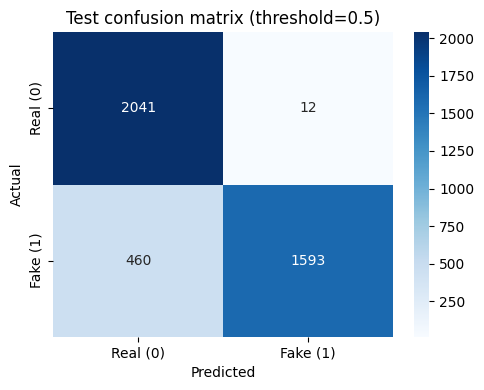

In [11]:
y_true = results_df["true_label"].to_numpy()
y_pred = results_df["pred_label"].to_numpy()

print(f"accuracy  = {accuracy_score(y_true, y_pred):.4f}")
print(f"macro-F1  = {f1_score(y_true, y_pred, average='macro'):.4f}")
print()
print(classification_report(y_true, y_pred, target_names=["Real (0)", "Fake (1)"]))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Real (0)", "Fake (1)"],
    yticklabels=["Real (0)", "Fake (1)"],
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Test confusion matrix (threshold=0.5)")
plt.tight_layout()
plt.show()

### `prob_fake` distribution: Real vs Fake

Sanity check the model's separation: Real (matched) pairs should sit near `prob_fake≈0`, Fake (unmatched)
pairs near `prob_fake≈1` — i.e. a huge shift/gap between the two groups' distributions.


In [12]:
prob_by_group = results_df.groupby("row_type")["prob_fake"].describe()
prob_by_group

,count,mean,std,min,25%,50%,75%,max
row_type,,,,,,,,
fake,2053.0,0.762198,0.326465,0.029166,0.632504,0.958240,0.975867,0.990406
real,2053.0,0.091006,0.078582,0.029688,0.049607,0.061645,0.102456,0.975058


## Step 5: Top-5 qualitative examples

For each selected row we look up the raw context in `test_pairs`:

-   **Real** examples: caption + image both come from the same article (`idx_caption == idx_image`).
-   **Fake** examples: the caption is from `idx_caption`'s article, but the displayed image belongs to
    a _different_ article (`idx_image`) — that mismatch is exactly what the model must catch.

Each card shows the **caption**, plus the **raw extracted text** (`pair_text` = title + caption) — the
exact string that was turned into BERT token embeddings for the model's text branch.


In [13]:
LABEL_NAMES = {0: "Real (matched)", 1: "Fake (unmatched)"}


def _content_key(row):
    """Identifies what a row actually *shows* (caption text + displayed image).
    The raw crawled data has ~600 duplicate (image, caption) pairs reused across
    different articles (e.g. generic 'Những hình ảnh được cắt ra trong clip' stills),
    which otherwise clutter top-K picks with visually identical repeats.
    """
    cap_pair = test_pairs[int(row["idx_caption"])]
    img_pair = test_pairs[int(row["idx_image"])]
    return (cap_pair["caption"], img_pair["image_path"])


def dedup_content(df_sorted, k):
    """Take the top-k rows from an already-sorted df, skipping rows whose
    (caption, displayed image) content duplicates one already picked.
    """
    seen = set()
    keep_idx = []
    for idx, row in df_sorted.iterrows():
        key = _content_key(row)
        if key in seen:
            continue
        seen.add(key)
        keep_idx.append(idx)
        if len(keep_idx) >= k:
            break
    return df_sorted.loc[keep_idx]


def _image_to_base64(path, max_size=320):
    """Load + downscale an image and return a base64 data-URI (for inline HTML)."""
    try:
        img = Image.open(path).convert("RGB")
    except FileNotFoundError:
        return None
    img.thumbnail((max_size, max_size))
    buf = BytesIO()
    img.save(buf, format="JPEG", quality=85)
    b64 = base64.b64encode(buf.getvalue()).decode("ascii")
    return f"data:image/jpeg;base64,{b64}"


def show_examples(df_subset, title):
    """Render examples as a pretty HTML card gallery — real CSS text wrapping for
    Vietnamese captions (green border = correct prediction, red = incorrect).
    Each card shows the caption, plus the raw extracted `pair_text`
    (title + caption) that feeds the text branch of the model.
    """
    n = len(df_subset)
    if n == 0:
        display(HTML(f"<p><b>{title}</b>: no examples found.</p>"))
        return

    cards = []
    for _, row in df_subset.iterrows():
        cap_pair = test_pairs[int(row["idx_caption"])]
        img_pair = test_pairs[int(row["idx_image"])]

        data_uri = _image_to_base64(img_pair["image_path"])
        img_html = (
            f'<img src="{data_uri}" style="width:100%;height:200px;object-fit:cover;'
            f'border-radius:8px 8px 0 0;">'
            if data_uri
            else '<div style="width:100%;height:200px;display:flex;align-items:center;'
            "justify-content:center;background:#eee;border-radius:8px 8px 0 0;"
            'color:#888;">image not found</div>'
        )

        border_color = "#2e7d32" if row["correct"] else "#c62828"
        badge_bg = "#e8f5e9" if row["correct"] else "#ffebee"
        badge_color = border_color

        note_html = ""
        if row["row_type"] == "fake":
            note_html = (
                f'<div style="font-size:11px;color:#888;font-style:italic;margin-top:4px;">'
                f"(ảnh từ bài khác, idx={row['idx_image']})</div>"
            )

        cards.append(
            f"""
        <div style="width:250px;border:2px solid {border_color};border-radius:10px;
                    overflow:hidden;box-shadow:0 2px 6px rgba(0,0,0,0.12);
                    font-family:-apple-system,sans-serif;background:#fff;">
          {img_html}
          <div style="padding:8px 10px;">
            <div style="display:inline-block;background:{badge_bg};color:{badge_color};
                        font-size:11px;font-weight:600;border-radius:4px;padding:2px 6px;
                        margin-bottom:6px;">
              true={LABEL_NAMES[row['true_label']]} · pred={LABEL_NAMES[row['pred_label']]}
              (p_fake={row['prob_fake']:.3f})
            </div>
            <div style="font-size:13px;line-height:1.45;color:#222;
                        word-wrap:break-word;">
              {html.escape(cap_pair["caption"])}
            </div>
            <div style="font-size:11px;line-height:1.4;color:#777;margin-top:6px;
                        word-wrap:break-word;border-top:1px dashed #ddd;padding-top:5px;">
              <span style="font-weight:600;color:#555;">raw text:</span>
              {html.escape(cap_pair["pair_text"])}
            </div>
            {note_html}
          </div>
        </div>
        """
        )

    gallery_html = f"""
    <h4 style="font-family:-apple-system,sans-serif;">{title}</h4>
    <div style="display:flex;flex-wrap:wrap;gap:14px;">{''.join(cards)}</div>
    """
    display(HTML(gallery_html))


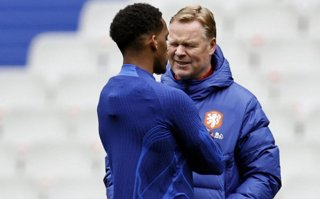
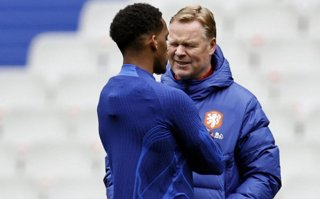
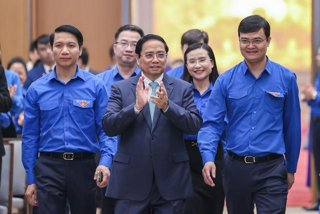
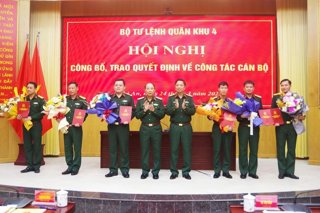
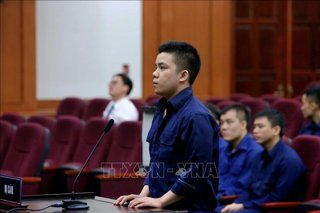
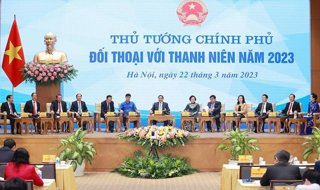
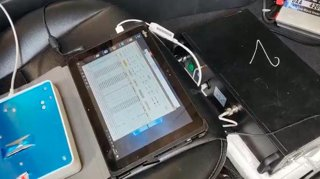
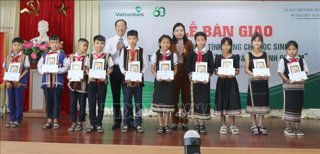

In [14]:
top5_correct = dedup_content(
    results_df[results_df["correct"]].sort_values("pred_confidence", ascending=False),
    TOP_K,
)
show_examples(top5_correct, f"Top {TOP_K} most confident CORRECT predictions")


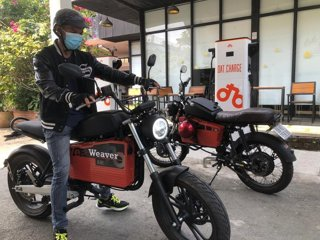
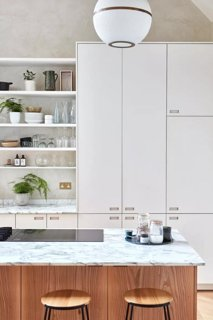
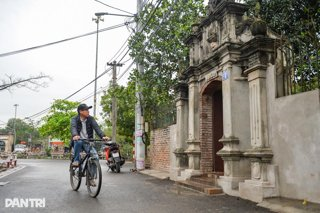
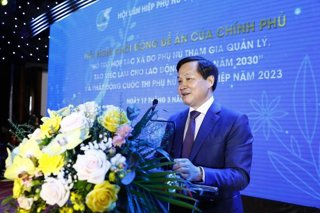
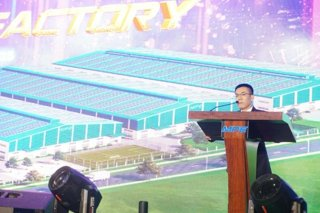
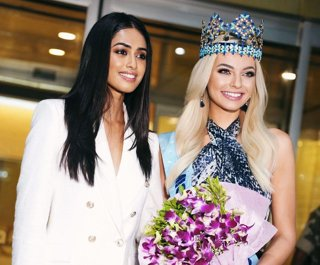
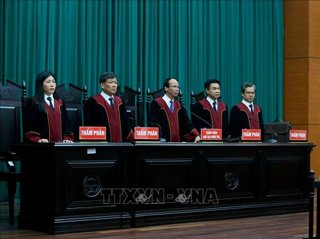
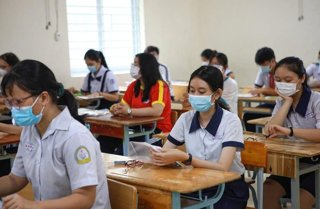

In [15]:
top5_incorrect = dedup_content(
    results_df[~results_df["correct"]].sort_values("pred_confidence", ascending=False),
    TOP_K,
)
show_examples(top5_incorrect, f"Top {TOP_K} most confident INCORRECT predictions")


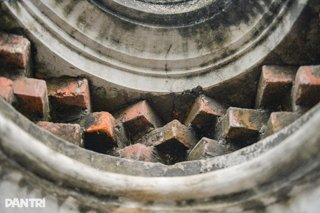
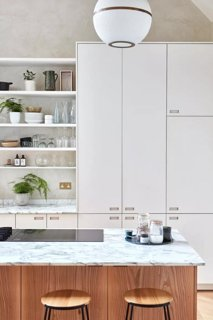
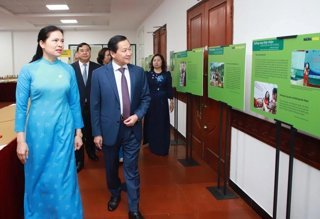
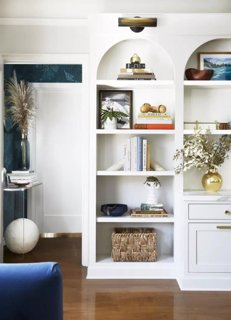
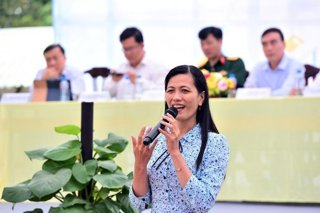
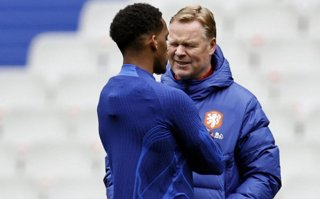
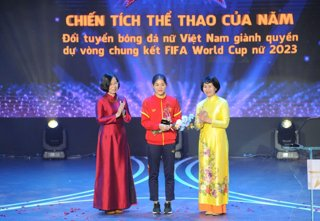
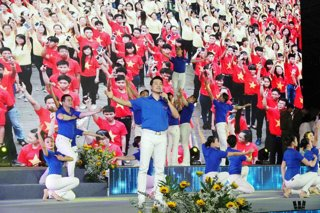


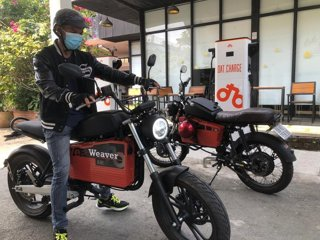
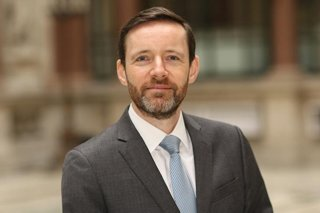
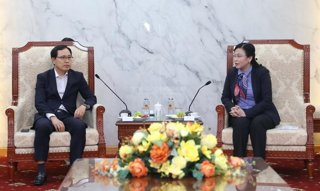
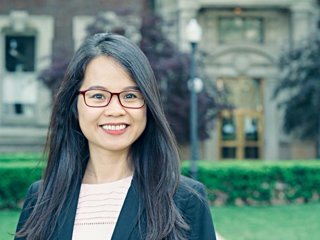
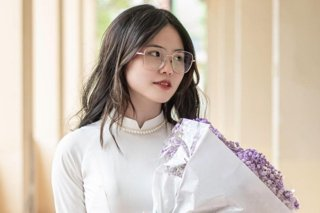
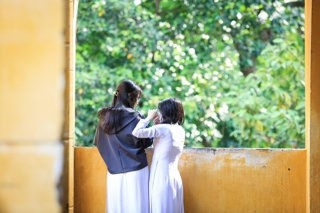

In [16]:
# Trường hợp true_label = Real (matched pair) — riêng cho lớp Real
top5_correct_real = dedup_content(
    results_df[(results_df["true_label"] == 0) & results_df["correct"]].sort_values(
        "pred_confidence", ascending=False
    ),
    TOP_K,
)
show_examples(
    top5_correct_real, f"Top {TOP_K} most confident CORRECT predictions (true=Real)"
)

top5_incorrect_real = dedup_content(
    results_df[(results_df["true_label"] == 0) & ~results_df["correct"]].sort_values(
        "pred_confidence", ascending=False
    ),
    TOP_K,
)
show_examples(
    top5_incorrect_real, f"Top {TOP_K} most confident INCORRECT predictions (true=Real)"
)

## Step 6: All false (misclassified) test cases

Toàn bộ các case bị dự đoán sai trong tập test (không chỉ top 5), sắp theo độ tin cậy giảm dần.
`show_all_false_cases_table()` in ra bảng đầy đủ; `show_examples(...)` có thể được gọi lại trên bất
kỳ lát cắt nào của `false_cases_df` để xem ảnh + caption.


In [17]:
false_cases_df = (
    results_df[~results_df["correct"]]
    .sort_values("pred_confidence", ascending=False)
    .reset_index(drop=True)
)

# Attach the raw caption text (not the article title) for each false case.
false_cases_df["caption"] = false_cases_df["idx_caption"].apply(
    lambda i: test_pairs[int(i)]["caption"]
)
# pair_text = title + caption — the exact raw text fed to the text branch.
false_cases_df["pair_text"] = false_cases_df["idx_caption"].apply(
    lambda i: test_pairs[int(i)]["pair_text"]
)

print(
    f"{len(false_cases_df)} / {len(results_df)} test examples misclassified "
    f"({len(false_cases_df) / len(results_df):.2%})"
)
print(false_cases_df["row_type"].value_counts().rename("count_by_row_type"))

false_cases_df[
    [
        "row_type",
        "true_label",
        "pred_label",
        "prob_fake",
        "pred_confidence",
        "idx_caption",
        "idx_image",
        "caption",
        "pair_text",
    ]
]

472 / 4106 test examples misclassified (11.50%)
row_type
fake    460
real     12
Name: count_by_row_type, dtype: int64


,row_type,true_label,pred_label,prob_fake,pred_confidence,idx_caption,idx_image,caption,pair_text
0,real,0,1,0.975058,0.975058,411,411,Một trạm sạc của Công ty Dat Bike ở TP.HCM,9 dự án xanh ở Việt Nam được Anh hỗ trợ nâng c...
1,real,0,1,0.975058,0.975058,1145,1145,Một trạm sạc của Công ty Dat Bike ở TP.HCM,9 dự án xanh ở Việt Nam được Anh hỗ trợ nâng c...
2,fake,1,0,0.029166,0.970834,700,697,Xem xét là bước quan trọng trong quá trình sắp...,Xem xét là bước quan trọng trong quá trình sắp...
3,fake,1,0,0.034721,0.965279,1750,1747,Mặc dù đã từng bị trúng đạn thời kỳ chiến tran...,Mặc dù đã từng bị trúng đạn thời kỳ chiến tran...
4,fake,1,0,0.034721,0.965279,1561,1558,Mặc dù đã từng bị trúng đạn thời kỳ chiến tran...,Mặc dù đã từng bị trúng đạn thời kỳ chiến tran...
...,...,...,...,...,...,...,...,...,...
467,fake,1,0,0.489028,0.510972,419,416,Cầu Phước Khánh (gói thầu J3) thuộc cao tốc Bế...,9 năm trắc trở xây cao tốc Bến Lức - Long Thàn...
468,fake,1,0,0.489813,0.510187,586,583,"Giá trị gia tăng thủy sản tăng 2,68% trong quý...",Nông nghiệp tiếp tục tăng trưởng trong quý I G...
469,fake,1,0,0.490461,0.509539,1852,1849,Cô Minh Tâm chia sẻ ngoài đi dạy vàhoạt động x...,Đứng lên từ biến cố cuộc đời Cô Minh Tâm chia ...
470,fake,1,0,0.490691,0.509309,1730,1759,U.23 Việt Nam gặp nhiều khó khăn,U.23 Việt Nam 0-0 U.23 Kyrgyzstan (luân lưu 4-...
